# Live LLM payoff experiment, decision traces, and pure-Nash benchmark

The primary actors use generic `LLMPolicy` through the provider configured in `.env` (`API_KEY` and `MODEL`). Each committed action includes the model's concise stated rationale. These explanations summarize its decision; they are not access to private internal reasoning.

**This notebook is configured for a live run.** It makes bounded API calls when re-executed. Set `USE_LIVE_API = False` for a zero-network deterministic fixture instead. Previously saved fake results deliberately hardcoded A=cooperate and B=defect; that fake assignment was not a model decision.

The pure-Nash solver runs separately and never supplies choices to the actors. Temporary job manifests are cleaned up; the returned internal artifact retains the config, events, explanations, and call metadata. No API key is stored in notebook cells or artifacts.


In [1]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from examples.llm_payoff_matrix import run_llm_job, run_live_job
from simulation_core.logging import replay

from simulation_core.logging import stream_action_trace

USE_LIVE_API = True
with stream_action_trace():
    artifact = run_live_job() if USE_LIVE_API else run_llm_job()
config = artifact.manifest.simulation
result = artifact.result
mode = "LIVE model" if USE_LIVE_API else "FAKE gateway (deterministic fixture)"
display(Markdown(f"**Mode:** {mode} · **Status:** {result.status} · **Committed rounds:** {result.final_state.tick}"))


{"tick": 1, "actor_id": "A", "action": {"actor_id": "A", "kind": "choose_move", "payload": {"move": "defect"}}, "rationale": "Defect strictly dominates: 5>3 if B cooperates, 1>0 if B defects. To maximize own payoff regardless of B's simultaneous unknown choice, defect."}


{"tick": 1, "actor_id": "B", "action": {"actor_id": "B", "kind": "choose_move", "payload": {"move": "defect"}}, "rationale": "One-shot Prisoner's Dilemma: defect gives 5 vs 3 if A cooperates and 1 vs 0 if A defects, so defect strictly dominates to maximize payoff regardless of A."}


**Mode:** LIVE model · **Status:** completed · **Committed rounds:** 1

## Configured payoff matrix and realized result

Each panel shows one actor's payoff. Rows are A's moves and columns are B's moves. The red rectangle marks the committed action profile, taken from the run's event log.


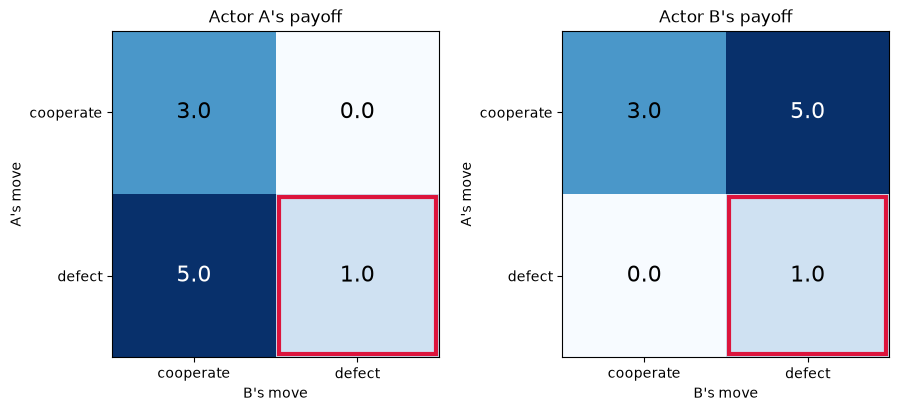

| Actor | Committed action | Realized payoff |
|---|---|---:|
| A | defect | 1 |
| B | defect | 1 |

In [2]:
choices = config.world.parameters["choices"]
row_moves, column_moves = choices["A"], choices["B"]
matrix = {(cell["moves"]["A"], cell["moves"]["B"]): cell["payoffs"]
          for cell in config.world.parameters["cells"]}
committed = result.events[-1]
chosen = {action.actor_id: action.payload["move"] for action in committed.actions}
row, column = row_moves.index(chosen["A"]), column_moves.index(chosen["B"])
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for player, (actor_id, ax) in enumerate(zip(("A", "B"), axes)):
    values = [[matrix[a, b][actor_id] for b in column_moves] for a in row_moves]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=5)
    for i in range(len(row_moves)):
        for j in range(len(column_moves)):
            ax.text(j, i, str(values[i][j]), ha="center", va="center",
                    color="white" if values[i][j] > 3 else "black", fontsize=16)
    ax.add_patch(Rectangle((column - .48, row - .48), .96, .96,
                           fill=False, edgecolor="crimson", linewidth=3))
    ax.set(xticks=range(len(column_moves)), xticklabels=column_moves,
           yticks=range(len(row_moves)), yticklabels=row_moves,
           xlabel="B's move", ylabel="A's move", title=f"Actor {actor_id}'s payoff")
plt.show()
display(Markdown("| Actor | Committed action | Realized payoff |\n|---|---|---:|\n" +
    "\n".join(f"| {aid} | {chosen[aid]} | {result.outcomes[-1].payoffs[aid]:g} |"
              for aid in ("A", "B"))))
if not USE_LIVE_API:
    assert result.outcomes[0].payoffs == {"A": 0.0, "B": 5.0}


## Mathematical benchmark and deviations

The benchmark uses pure strategies, complete information, and a reported payoff tolerance. For this game the unique pure equilibrium is defect/defect with payoffs (1, 1). A positive deviation gain means an actor could improve its own payoff by changing only its own move while the other move stays fixed.

Payoff deltas are **actor-run payoff minus equilibrium payoff**. The solver does not replace the primary actors' choices. Every equilibrium is retained when there are multiple; no equilibrium is selected silently.


Benchmark: solved
Solution concept: pure_nash
Diagnostics: {'payoff_tolerance': 1e-09, 'scope': 'Pure strategies only; no conclusion about mixed equilibria.'}
Profiles evaluated: 4
Compared tick: 1
Configuration SHA-256: 0998a6478520da9680070cbf98dc69863df2f2bb37bb4b035d817031b715397a


| Equilibrium | Actor | Actor-run action | Nash action | Actor payoff | Nash payoff | Delta | Deviation gain |
|---:|---|---|---|---:|---:|---:|---:|
| 0 | A | defect | defect | 1 | 1 | +0 | 0 |
| 0 | B | defect | defect | 1 | 1 | +0 | 0 |

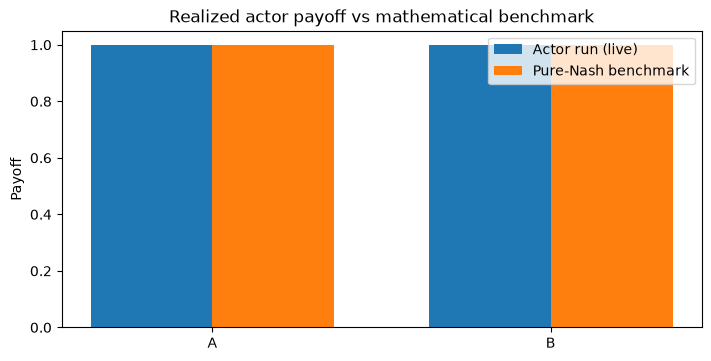

In [3]:
benchmark = artifact.benchmark
assert benchmark is not None
print("Benchmark:", benchmark.result.status)
print("Solution concept:", benchmark.result.solution_concept)
print("Diagnostics:", benchmark.result.diagnostics)
print("Profiles evaluated:", benchmark.result.profiles_evaluated)
print("Compared tick:", benchmark.comparison_tick)
print("Configuration SHA-256:", benchmark.config_sha256)
if benchmark.result.status in {"solved", "multiple"}:
    rows = ["| Equilibrium | Actor | Actor-run action | Nash action | Actor payoff | Nash payoff | Delta | Deviation gain |",
            "|---:|---|---|---|---:|---:|---:|---:|"]
    for comparison in benchmark.comparisons:
        equilibrium = benchmark.result.equilibria[comparison.equilibrium_index]
        reference = {action.actor_id: action.payload["move"] for action in equilibrium.actions}
        for aid in ("A", "B"):
            rows.append(f"| {comparison.equilibrium_index} | {aid} | {chosen[aid]} | {reference[aid]} | "
                        f"{result.outcomes[-1].payoffs[aid]:g} | {equilibrium.outcome.payoffs[aid]:g} | "
                        f"{comparison.payoff_deltas[aid]:+g} | {benchmark.observed_regrets[aid]:g} |")
    display(Markdown("\n".join(rows)))
    # This fixture has one equilibrium. Keep all comparisons in the artifact.
    assert len(benchmark.result.equilibria) == 1
    equilibrium = benchmark.result.equilibria[0]
    fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
    actor_ids = ("A", "B")
    ax.bar([-.18, .82], [result.outcomes[-1].payoffs[aid] for aid in actor_ids],
           width=.36, label=f"Actor run ({'live' if USE_LIVE_API else 'fake gateway'})")
    ax.bar([.18, 1.18], [equilibrium.outcome.payoffs[aid] for aid in actor_ids],
           width=.36, label="Pure-Nash benchmark")
    ax.set(xticks=[0, 1], xticklabels=actor_ids, ylabel="Payoff", title="Realized actor payoff vs mathematical benchmark")
    ax.axhline(0, color="black", linewidth=.6)
    ax.legend()
    plt.show()
else:
    display(Markdown("Benchmark unavailable or no pure equilibrium; see status and diagnostics above."))
if not USE_LIVE_API:
    assert benchmark.comparisons[0].payoff_deltas == {"A": -1.0, "B": 4.0}
    assert benchmark.observed_regrets == {"A": 1.0, "B": 0.0}


## Why each actor chose its action
Every committed turn is listed below. Live-mode explanations come from the model response. Fake-mode explanations are labeled fixtures. The actors choose simultaneously, so neither knows the other’s current uncommitted move.

In [4]:
for event in result.events:
    for decision in event.decisions:
        print(f"Turn {event.state.tick} | Actor {decision.action.actor_id} | {decision.action.kind} {decision.action.payload}")
        print(f"Stated rationale: {decision.rationale}\n")
        assert decision.rationale


Turn 1 | Actor A | choose_move {'move': 'defect'}
Stated rationale: Defect strictly dominates: 5>3 if B cooperates, 1>0 if B defects. To maximize own payoff regardless of B's simultaneous unknown choice, defect.

Turn 1 | Actor B | choose_move {'move': 'defect'}
Stated rationale: One-shot Prisoner's Dilemma: defect gives 5 vs 3 if A cooperates and 1 vs 0 if A defects, so defect strictly dominates to maximize payoff regardless of A.



## Model-call provenance

Each committed event records the bounded calls used to produce its actions. The internal artifact includes authorized prompts and responses and may contain private information. The table below shows only call metadata. State replay reads recorded commits and never recalls the model.


In [5]:
display(Markdown("| Actor | Mode | Model | Attempt | Status | Input tokens | Output tokens |\n"
                 "|---|---|---|---:|---|---:|---:|\n" +
    "\n".join(f"| {call.actor_id} | {call.mode} | {call.model} | {call.attempt} | {call.status} | "
              f"{call.input_tokens} | {call.output_tokens} |" for call in result.model_calls)))
assert tuple(call for event in result.events for call in event.model_calls) == result.model_calls


| Actor | Mode | Model | Attempt | Status | Input tokens | Output tokens |
|---|---|---|---:|---|---:|---:|
| A | live | muse-spark-1.3-contributor | 1 | accepted | 691 | 374 |
| B | live | muse-spark-1.3-contributor | 1 | accepted | 691 | 258 |

## Reconstruct the committed trajectory

Replay reads initialization and committed snapshots. It makes no policy or mechanism calls. This development notebook has access to the internal log; production actor observations never receive it.


In [6]:
states = replay(result.events)
assert states[-1] == result.final_state
assert result == type(result).model_validate_json(result.model_dump_json())
display(Markdown("| Event | Tick | Phase | Public action history |\n|---|---:|---|---|\n" +
    "\n".join(f"| {event.kind} | {state.tick} | {state.phase} | {state.public['history']} |"
              for event, state in zip(result.events, states))))
print("Replay matches the final committed state; JSON round-trip passed.")


| Event | Tick | Phase | Public action history |
|---|---:|---|---|
| initialized | 0 | act | [] |
| committed | 1 | finished | [{'A': 'defect', 'B': 'defect'}] |

Replay matches the final committed state; JSON round-trip passed.


## Reusable toolkit and experiment configuration
The base payoff data lives in `src/examples/configs/prisoners_dilemma.json`; the typed builder in `examples.llm_payoff_matrix` selects LLM policies, explicitly exposes the payoff table, records assumptions, and configures the benchmark. The registry exposes approved interfaces and schemas to a simulation-creating coding agent.

In [7]:
from components.library import standard_registry
inventory = standard_registry().describe()
print("Policy interfaces:", inventory["policies"])
print("Mechanisms:", inventory["mechanisms"])
print("Protocols:", inventory["protocols"])
print("Configured choices:", config.world.parameters["choices"])
print("Configured permissions:", {aid: p.model_dump() for aid, p in config.permissions.items()})

print("User request:", artifact.manifest.request.hypothesis)
print("Supplied inputs:", [item.name for item in artifact.manifest.request.supplied_inputs])
print("The temporary job manifest has been cleaned up; its validated contents remain in artifact.manifest.")


Policy interfaces: ['scripted.v1']
Mechanisms: ['normal_form.v1', 'recording.v1']
Protocols: ['simultaneous.v1']
Configured choices: {'A': ['cooperate', 'defect'], 'B': ['cooperate', 'defect']}
Configured permissions: {'A': {'public_fields': ('history', 'payoffs', 'game'), 'private_fields': (), 'readable_memory': True, 'writable_private_fields': (), 'writable_memory': True}, 'B': {'public_fields': ('history', 'payoffs', 'game'), 'private_fields': (), 'readable_memory': True, 'writable_private_fields': (), 'writable_memory': True}}
User request: What moves do the configured LLM policies choose, and how do they deviate from pure Nash?
Supplied inputs: ['payoff table']
The temporary job manifest has been cleaned up; its validated contents remain in artifact.manifest.


## Cross-experiment check
The same runtime also executes a separately configured measurement collection fixture. It uses three actors, numeric payloads, different public/private fields, and no payoffs. This is an extensibility fixture, not a scientific model.

In [8]:
from examples.measurements import run_experiment as run_measurements
measurements = run_measurements()
assert measurements.outcomes[-1].payoffs == {}
assert replay(measurements.events)[-1] == measurements.final_state
print("Measurement experiment:", measurements.status)
print("Recorded rounds:", len(measurements.final_state.public["readings"]))
print("Metrics:", measurements.outcomes[-1].metrics)


Measurement experiment: completed
Recorded rounds: 2
Metrics: {'received': 3}


## Experiment assumptions

These structured assumptions come from the resolved configuration. Each records its exact configuration path, value, source, and rationale; the summary below shows source, path, and rationale. Values remain available in `artifact.manifest.simulation.assumptions`.


In [9]:
display(Markdown("\n".join(
    f"- **{assumption.source}** `{assumption.path}`: {assumption.rationale}"
    for assumption in result.assumptions)))


- **user** `/world/parameters/cells`: The example request supplies this payoff table; the numbers are not empirically calibrated.
- **textbook** `/protocol_id`: A normal-form game uses simultaneous choices.
- **default** `/permissions/A`: Both players know the full payoff table and choices, observe committed past moves, and see only their own private state.
- **default** `/permissions/B`: Both players know the full payoff table and choices, observe committed past moves, and see only their own private state.
- **default** `/world/actors/0/policy_parameters`: Use the configured model and own-payoff objective with bounded calls; model/persona behavior is synthetic and uncalibrated.
- **default** `/world/actors/1/policy_parameters`: Use the configured model and own-payoff objective with bounded calls; model/persona behavior is synthetic and uncalibrated.